# Trial: AlphaEarth → residential vs non-residential

**Goal.** Train a small classifier on **AlphaEarth Satellite Embedding V1** (64-D) to predict
**residential vs non-residential**, evaluate across **US metro regions**, and map performance.

**Label source.** Overture buildings (`subtype`) from the public release — only rows with a
non-null subtype (OSM-derived). Unlabeled footprints are excluded (never treated as negatives).

**Features.** 2024 annual AlphaEarth embeddings sampled at building centroids via Google Earth Engine.

**Requires.** Earth Engine auth (`earthengine authenticate` + a Cloud project). Overture cells
need network access to the public S3 GeoParquet bucket.


## Setup

```bash
pip install -r requirements.txt
# one-time EE auth (no gcloud needed on this host):
earthengine authenticate --auth_mode=notebook
```

Open the printed URL, sign in, paste the auth code back into the terminal.  
Set `EE_PROJECT` below to your Earth Engine Cloud project id.


In [5]:
from __future__ import annotations

import json
import os
import time
import warnings
from pathlib import Path

import duckdb
import ee
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", lambda x: f"{x:0.3f}")

ROOT = Path(".").resolve()
if not (ROOT / "requirements.txt").exists() and (ROOT.parent / "requirements.txt").exists():
    ROOT = ROOT.parent
OUT_DIR = ROOT / "outputs" / "trial_residential"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE = OUT_DIR / "building_embeddings.parquet"

RELEASE = "2026-08-19.0"
BUILDINGS = f"s3://overturemaps-us-west-2/release/{RELEASE}/theme=buildings/type=building/*"
EMBED_YEAR = 2024
N_PER_CLASS = 200          # labeled samples per class per region (trial scale)
EE_BATCH = 400             # reduceRegions batch size
RANDOM_STATE = 42

# Earth Engine Cloud project id (required). Override via env if set.
EE_PROJECT = 'ee-kedarvaidya0504'

print("ROOT:", ROOT)
print("Outputs:", OUT_DIR)
print("EE_PROJECT:", EE_PROJECT)


ROOT: /data/users/kv133/Alpha-Earth-Embeddings-Research
Outputs: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/trial_residential
EE_PROJECT: ee-kedarvaidya0504


## US regions

Compact metro bboxes spanning Northeast, Midwest, South, and West. Labels are denser in
well-mapped cores; these AOIs are intentionally small to keep Overture + EE queries cheap.


In [2]:
US_REGIONS: dict[str, tuple[float, float, float, float]] = {
    # name: (xmin, ymin, xmax, ymax)  — lon/lat
    "Boston_NE": (-71.20, 42.28, -70.95, 42.42),
    "NYC_NE": (-74.05, 40.68, -73.90, 40.82),
    "Chicago_MW": (-87.75, 41.80, -87.55, 41.95),
    "Atlanta_SE": (-84.45, 33.70, -84.30, 33.85),
    "Houston_S": (-95.50, 29.70, -95.25, 29.85),
    "Denver_W": (-105.05, 39.68, -104.90, 39.80),
    "Phoenix_SW": (-112.15, 33.40, -111.95, 33.55),
    "Seattle_NW": (-122.40, 47.55, -122.25, 47.68),
    "LA_W": (-118.35, 34.00, -118.20, 34.12),
}


def region_centroid(bbox: tuple[float, float, float, float]) -> tuple[float, float]:
    xmin, ymin, xmax, ymax = bbox
    return (0.5 * (xmin + xmax), 0.5 * (ymin + ymax))


region_meta = pd.DataFrame(
    [
        {
            "region": name,
            "lon": region_centroid(b)[0],
            "lat": region_centroid(b)[1],
            "xmin": b[0],
            "ymin": b[1],
            "xmax": b[2],
            "ymax": b[3],
        }
        for name, b in US_REGIONS.items()
    ]
)
region_meta


,region,lon,lat,xmin,ymin,xmax,ymax
0,Boston_NE,-71.075,42.350,-71.200,42.280,-70.950,42.420
1,NYC_NE,-73.975,40.750,-74.050,40.680,-73.900,40.820
2,Chicago_MW,-87.650,41.875,-87.750,41.800,-87.550,41.950
3,Atlanta_SE,-84.375,33.775,-84.450,33.700,-84.300,33.850
4,Houston_S,-95.375,29.775,-95.500,29.700,-95.250,29.850
5,Denver_W,-104.975,39.740,-105.050,39.680,-104.900,39.800
6,Phoenix_SW,-112.050,33.475,-112.150,33.400,-111.950,33.550
7,Seattle_NW,-122.325,47.615,-122.400,47.550,-122.250,47.680
8,LA_W,-118.275,34.060,-118.350,34.000,-118.200,34.120


## 1. Sample Overture building labels

Binary target from `subtype`:

- `1` = `residential`
- `0` = any other non-null subtype (commercial, industrial, education, …)

Stratified sample of `N_PER_CLASS` per side per region (or all available if fewer).


In [3]:
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("INSTALL spatial; LOAD spatial;")
con.execute("SET s3_region='us-west-2';")
con.execute("SET s3_access_key_id='';")
con.execute("SET s3_secret_access_key='';")
print("DuckDB ready ·", RELEASE)


def sample_region(name: str, bbox: tuple[float, float, float, float], n_per_class: int) -> pd.DataFrame:
    xmin, ymin, xmax, ymax = bbox
    sql = f"""
    WITH b AS (
      SELECT
        id,
        subtype,
        class,
        ST_X(ST_Centroid(geometry)) AS lon,
        ST_Y(ST_Centroid(geometry)) AS lat
      FROM read_parquet('{BUILDINGS}', hive_partitioning=1)
      WHERE bbox.xmin BETWEEN {xmin} AND {xmax}
        AND bbox.ymin BETWEEN {ymin} AND {ymax}
        AND subtype IS NOT NULL
        AND geometry IS NOT NULL
    ),
    labeled AS (
      SELECT
        id, subtype, class, lon, lat,
        CASE WHEN subtype = 'residential' THEN 1 ELSE 0 END AS y
      FROM b
      WHERE lon BETWEEN {xmin} AND {xmax}
        AND lat BETWEEN {ymin} AND {ymax}
    ),
    sampled AS (
      SELECT * FROM (
        SELECT *, row_number() OVER (PARTITION BY y ORDER BY hash(id)) AS rn
        FROM labeled
      ) t
      WHERE rn <= {n_per_class}
    )
    SELECT
      id,
      '{name}' AS region,
      subtype,
      class,
      lon,
      lat,
      y
    FROM sampled
    """
    return con.execute(sql).df()


cache_labels = OUT_DIR / "building_labels.parquet"
if cache_labels.exists():
    labels = pd.read_parquet(cache_labels)
    print("Loaded cached labels:", cache_labels)
else:
    frames = []
    for name, bbox in US_REGIONS.items():
        print(f"Sampling · {name} ...", flush=True)
        frames.append(sample_region(name, bbox, N_PER_CLASS))
    labels = pd.concat(frames, ignore_index=True)
    labels.to_parquet(cache_labels, index=False)
    print("Wrote", cache_labels)

summary = (
    labels.groupby("region")
    .agg(n=("y", "size"), n_res=("y", "sum"), pct_res=("y", "mean"))
    .assign(n_nonres=lambda d: d["n"] - d["n_res"], pct_res=lambda d: 100 * d["pct_res"])
)
summary


DuckDB ready · 2026-08-19.0
Sampling · Boston_NE ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Sampling · NYC_NE ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Sampling · Chicago_MW ...


...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Sampling · LA_W ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/trial_residential/building_labels.parquet


,n,n_res,pct_res,n_nonres
region,,,,
Atlanta_SE,400,200,50.000,200
Boston_NE,400,200,50.000,200
Chicago_MW,400,200,50.000,200
Denver_W,400,200,50.000,200
Houston_S,400,200,50.000,200
LA_W,400,200,50.000,200
NYC_NE,400,200,50.000,200
Phoenix_SW,400,200,50.000,200
Seattle_NW,400,200,50.000,200


## 2. Authenticate Earth Engine & extract AlphaEarth embeddings

Bands `A00`–`A63` (64-D). We take the **pixel at the building centroid** (`Reducer.first`, 10 m).
Results are cached to parquet so re-runs skip EE.


In [6]:
def init_ee(project: str) -> None:
    if not project or project == "YOUR_EE_PROJECT_ID":
        raise ValueError(
            "Set EE_PROJECT to your Earth Engine Cloud project id "
            "(cell above or export EE_PROJECT=...)."
        )
    try:
        ee.Initialize(project=project)
    except Exception:
        # No gcloud on this host — use notebook OAuth (URL + paste code).
        ee.Authenticate(auth_mode="notebook")
        ee.Initialize(project=project)
    print("Earth Engine initialized · project =", project)


def annual_embedding_image(year: int) -> ee.Image:
    return (
        ee.ImageCollection("GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL")
        .filterDate(f"{year}-01-01", f"{year + 1}-01-01")
        .mosaic()
    )


BANDS = [f"A{i:02d}" for i in range(64)]


def extract_embeddings(df: pd.DataFrame, year: int = EMBED_YEAR, batch_size: int = EE_BATCH) -> pd.DataFrame:
    # Sample 64-D embeddings at lon/lat points; returns df with A00..A63 columns.
    init_ee(EE_PROJECT)
    img = annual_embedding_image(year)
    rows: list[dict] = []
    n = len(df)
    for start in range(0, n, batch_size):
        batch = df.iloc[start : start + batch_size]
        feats = []
        for _, r in batch.iterrows():
            feats.append(
                ee.Feature(
                    ee.Geometry.Point([float(r["lon"]), float(r["lat"])]),
                    {"row_id": str(r["id"]), "region": r["region"], "y": int(r["y"])},
                )
            )
        fc = ee.FeatureCollection(feats)
        sampled = img.reduceRegions(
            collection=fc,
            reducer=ee.Reducer.first(),
            scale=10,
            tileScale=4,
        )
        print(f"EE reduceRegions · {start}:{start + len(batch)} / {n}", flush=True)
        info = sampled.getInfo()
        for f in info["features"]:
            props = f["properties"]
            row = {
                "id": props.get("row_id"),
                "region": props.get("region"),
                "y": props.get("y"),
            }
            for b in BANDS:
                row[b] = props.get(b)
            rows.append(row)
        time.sleep(0.5)  # be gentle with EE
    out = pd.DataFrame(rows)
    out = out.dropna(subset=BANDS).reset_index(drop=True)
    return out


if CACHE.exists():
    data = pd.read_parquet(CACHE)
    print("Loaded cached embeddings:", CACHE, "· n =", len(data))
else:
    data = extract_embeddings(labels)
    data = data.merge(labels[["id", "lon", "lat", "subtype", "class"]], on="id", how="left")
    data.to_parquet(CACHE, index=False)
    print("Wrote", CACHE, "· n =", len(data))

print(data.groupby(["region", "y"]).size().unstack(fill_value=0))
print("Feature matrix:", data[BANDS].shape)


Earth Engine initialized · project = ee-kedarvaidya0504
EE reduceRegions · 0:400 / 3600
EE reduceRegions · 400:800 / 3600
EE reduceRegions · 800:1200 / 3600
EE reduceRegions · 1200:1600 / 3600
EE reduceRegions · 1600:2000 / 3600
EE reduceRegions · 2000:2400 / 3600
EE reduceRegions · 2400:2800 / 3600
EE reduceRegions · 2800:3200 / 3600
EE reduceRegions · 3200:3600 / 3600
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/trial_residential/building_embeddings.parquet · n = 3600
y             0    1
region              
Atlanta_SE  200  200
Boston_NE   200  200
Chicago_MW  200  200
Denver_W    200  200
Houston_S   200  200
LA_W        200  200
NYC_NE      200  200
Phoenix_SW  200  200
Seattle_NW  200  200
Feature matrix: (3600, 64)


## 3. Train classifier

Baseline: L2 logistic regression on standardized 64-D embeddings.

Two evaluations:

1. **Pooled holdout** — random 80/20 stratified split (optimistic upper bound).
2. **Leave-one-region-out (LORO)** — train on all other metros, test on held-out metro
   (better estimate of geographic transfer).


In [7]:
X = data[BANDS].to_numpy(dtype=np.float64)
y = data["y"].to_numpy(dtype=int)
groups = data["region"].to_numpy()

clf = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "lr",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

# --- pooled holdout ---
X_tr, X_te, y_tr, y_te, reg_tr, reg_te = train_test_split(
    X, y, groups, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
clf.fit(X_tr, y_tr)
proba_te = clf.predict_proba(X_te)[:, 1]
pred_te = (proba_te >= 0.5).astype(int)

pooled = {
    "accuracy": float(accuracy_score(y_te, pred_te)),
    "f1_residential": float(f1_score(y_te, pred_te, pos_label=1)),
    "f1_macro": float(f1_score(y_te, pred_te, average="macro")),
    "roc_auc": float(roc_auc_score(y_te, proba_te)),
    "n_train": int(len(y_tr)),
    "n_test": int(len(y_te)),
}
print("Pooled holdout")
print(json.dumps(pooled, indent=2))
print(classification_report(y_te, pred_te, target_names=["non_residential", "residential"]))


Pooled holdout
{
  "accuracy": 0.8263888888888888,
  "f1_residential": 0.8322147651006712,
  "f1_macro": 0.8261793249963787,
  "roc_auc": 0.8984645061728395,
  "n_train": 2880,
  "n_test": 720
}
                 precision    recall  f1-score   support

non_residential       0.85      0.79      0.82       360
    residential       0.81      0.86      0.83       360

       accuracy                           0.83       720
      macro avg       0.83      0.83      0.83       720
   weighted avg       0.83      0.83      0.83       720



In [8]:
# --- leave-one-region-out ---
regions = sorted(data["region"].unique())
loro_rows = []
oof_pred = np.full(len(data), -1, dtype=int)
oof_proba = np.full(len(data), np.nan)

for holdout in regions:
    mask_te = data["region"] == holdout
    mask_tr = ~mask_te
    if mask_te.sum() < 20 or mask_tr.sum() < 50:
        print(f"Skip {holdout}: too few samples")
        continue
    model = Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "lr",
                LogisticRegression(
                    max_iter=2000,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )
    model.fit(X[mask_tr], y[mask_tr])
    proba = model.predict_proba(X[mask_te])[:, 1]
    pred = (proba >= 0.5).astype(int)
    oof_pred[mask_te.to_numpy()] = pred
    oof_proba[mask_te.to_numpy()] = proba
    loro_rows.append(
        {
            "region": holdout,
            "n_test": int(mask_te.sum()),
            "n_res": int(y[mask_te].sum()),
            "n_nonres": int((y[mask_te] == 0).sum()),
            "accuracy": float(accuracy_score(y[mask_te], pred)),
            "f1_residential": float(f1_score(y[mask_te], pred, pos_label=1, zero_division=0)),
            "f1_macro": float(f1_score(y[mask_te], pred, average="macro", zero_division=0)),
            "roc_auc": float(roc_auc_score(y[mask_te], proba))
            if len(np.unique(y[mask_te])) > 1
            else np.nan,
        }
    )

loro = pd.DataFrame(loro_rows).sort_values("f1_macro", ascending=False)
loro_path = OUT_DIR / "loro_metrics.csv"
loro.to_csv(loro_path, index=False)
print("Wrote", loro_path)
loro


Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/trial_residential/loro_metrics.csv


,region,n_test,n_res,n_nonres,accuracy,f1_residential,f1_macro,roc_auc
0,Atlanta_SE,400,200,200,0.868,0.876,0.867,0.921
8,Seattle_NW,400,200,200,0.853,0.861,0.852,0.929
5,LA_W,400,200,200,0.835,0.853,0.832,0.938
7,Phoenix_SW,400,200,200,0.805,0.825,0.802,0.872
4,Houston_S,400,200,200,0.800,0.777,0.798,0.912
2,Chicago_MW,400,200,200,0.785,0.790,0.785,0.875
1,Boston_NE,400,200,200,0.743,0.748,0.742,0.804
3,Denver_W,400,200,200,0.672,0.737,0.651,0.665
6,NYC_NE,400,200,200,0.580,0.491,0.567,0.668


## 4. Performance map (US metros)

Bubble map: region centroid sized by test `n`, colored by leave-one-region-out **macro F1**.


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/trial_residential/us_region_performance_map.png


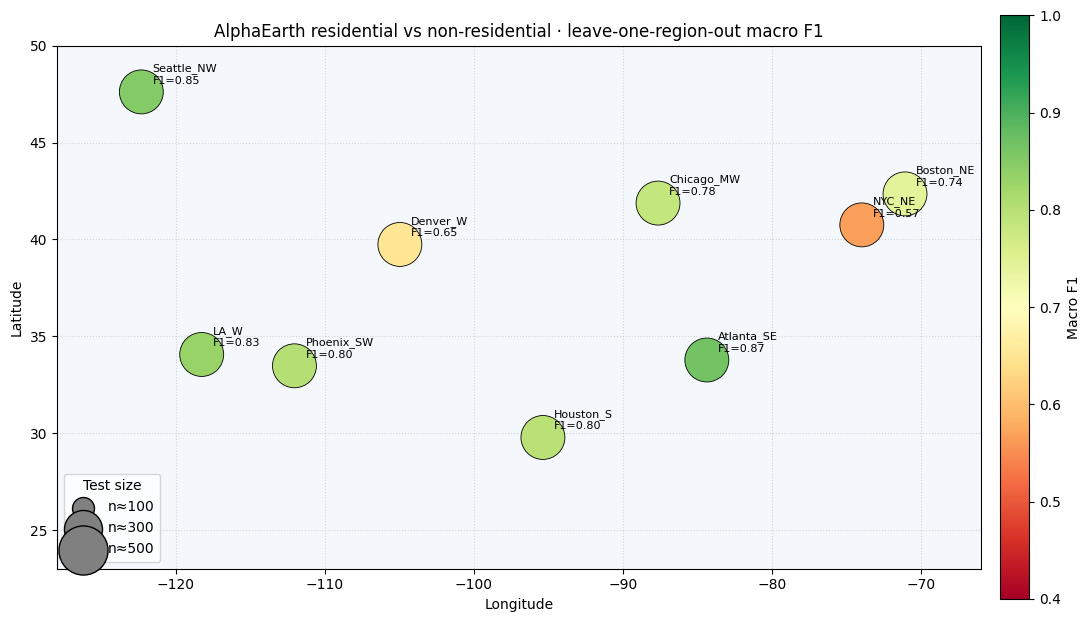

In [9]:
map_df = loro.merge(region_meta[["region", "lon", "lat"]], on="region", how="left")

fig, ax = plt.subplots(figsize=(11, 6.5))
# continental US extent
ax.set_xlim(-128, -66)
ax.set_ylim(23, 50)
ax.set_aspect(1.3)
ax.set_facecolor("#f4f7fb")
ax.grid(True, linestyle=":", alpha=0.5)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("AlphaEarth residential vs non-residential · leave-one-region-out macro F1")

sc = ax.scatter(
    map_df["lon"],
    map_df["lat"],
    c=map_df["f1_macro"],
    s=map_df["n_test"] * 2.5,
    cmap="RdYlGn",
    vmin=0.4,
    vmax=1.0,
    edgecolors="k",
    linewidths=0.6,
    zorder=3,
)
cbar = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label("Macro F1")

for _, r in map_df.iterrows():
    ax.annotate(
        f"{r['region']}\nF1={r['f1_macro']:.2f}",
        (r["lon"], r["lat"]),
        textcoords="offset points",
        xytext=(8, 6),
        fontsize=8,
        ha="left",
    )

for n, label in [(100, "n≈100"), (300, "n≈300"), (500, "n≈500")]:
    ax.scatter([], [], s=n * 2.5, c="gray", edgecolors="k", label=label)
ax.legend(frameon=True, title="Test size", loc="lower left")

fig.tight_layout()
map_path = OUT_DIR / "us_region_performance_map.png"
fig.savefig(map_path, dpi=150)
print("Saved", map_path)
plt.show()


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/trial_residential/us_region_performance_bars.png


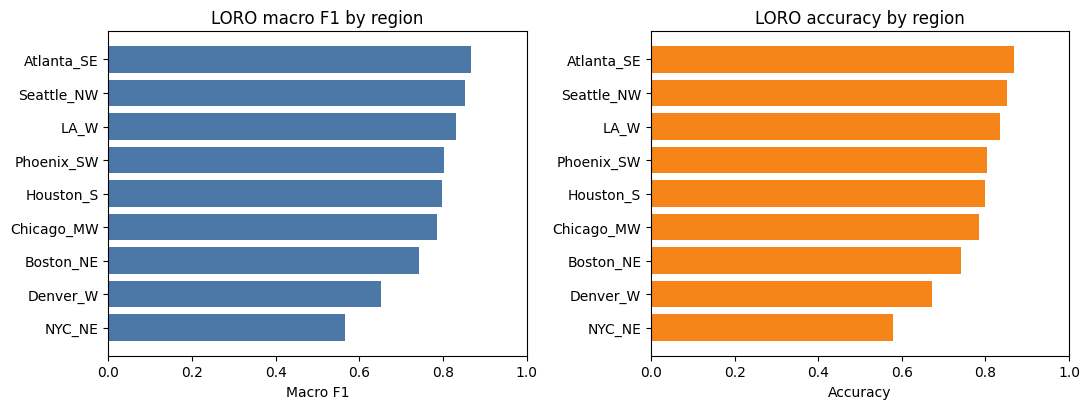

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
order = map_df.sort_values("f1_macro")["region"]
plot_df = map_df.set_index("region").loc[order]

axes[0].barh(plot_df.index, plot_df["f1_macro"], color="#4C78A8")
axes[0].set_xlabel("Macro F1")
axes[0].set_title("LORO macro F1 by region")
axes[0].set_xlim(0, 1)

axes[1].barh(plot_df.index, plot_df["accuracy"], color="#F58518")
axes[1].set_xlabel("Accuracy")
axes[1].set_title("LORO accuracy by region")
axes[1].set_xlim(0, 1)

fig.tight_layout()
bar_path = OUT_DIR / "us_region_performance_bars.png"
fig.savefig(bar_path, dpi=150)
print("Saved", bar_path)
plt.show()


## 5. Snapshot & next steps

**Interpretation tips**

- Pooled holdout usually looks better than LORO — expect a drop when transferring across metros.
- Regions with thinner OSM labeling may have noisier `subtype` GT even when present.
- Centroid sampling ignores footprint extent; Phase 2 can mean-pool embeddings over the polygon.

**Next experiments**

- Swap LR for `HistGradientBoostingClassifier` / light MLP.
- Add neighborhood context (mean-pool 50 m / 200 m buffers).
- Multi-class (`house` vs `apartments` vs non-res) once SF/MF labels are dense enough.
- Places joins / GHS-OBAT for noisier positives outside OSM-rich cores.


In [11]:
snapshot = {
    "overture_release": RELEASE,
    "embedding_year": EMBED_YEAR,
    "n_buildings": int(len(data)),
    "n_per_class_target": N_PER_CLASS,
    "regions": list(US_REGIONS.keys()),
    "pooled_holdout": pooled,
    "loro_macro_f1_mean": float(loro["f1_macro"].mean()),
    "loro_accuracy_mean": float(loro["accuracy"].mean()),
    "loro_by_region": loro.to_dict(orient="records"),
    "outputs": sorted(p.name for p in OUT_DIR.iterdir()),
}
snap_path = OUT_DIR / "trial_snapshot.json"
snap_path.write_text(json.dumps(snapshot, indent=2))
print("Wrote", snap_path)
print(json.dumps({k: snapshot[k] for k in ["n_buildings", "pooled_holdout", "loro_macro_f1_mean", "loro_accuracy_mean"]}, indent=2))


Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/trial_residential/trial_snapshot.json
{
  "n_buildings": 3600,
  "pooled_holdout": {
    "accuracy": 0.8263888888888888,
    "f1_residential": 0.8322147651006712,
    "f1_macro": 0.8261793249963787,
    "roc_auc": 0.8984645061728395,
    "n_train": 2880,
    "n_test": 720
  },
  "loro_macro_f1_mean": 0.7662720882347611,
  "loro_accuracy_mean": 0.7711111111111112
}
